## Mini-Batch Gradient Descent using DataLoaders

In [1]:
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
data = fetch_california_housing(as_frame=False)
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [2]:
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, random_state=42)

In [3]:
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
X_valid = torch.FloatTensor(X_valid)
y_train = torch.FloatTensor(y_train).reshape(-1,1)
y_valid = torch.FloatTensor(y_valid).reshape(-1,1)
y_test = torch.FloatTensor(y_test).reshape(-1,1)

In [4]:
n_features = X_train.shape[1] # No. of Features or Columns

In [5]:
from torch import nn
model = nn.Sequential(
    nn.Linear(n_features,50),
    nn.ReLU(),
    nn.Linear(50,50),
    nn.ReLU(),
    nn.Linear(50,1)
)

In [6]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) # SRS
print(train_dataset[:3])

(tensor([[0.1288, 0.7451, 0.0215, 0.0271, 0.0393, 0.0025, 0.2000, 0.4661],
        [0.6645, 0.4510, 0.0473, 0.0258, 0.0629, 0.0017, 0.1266, 0.6006],
        [0.0808, 0.7843, 0.0214, 0.0231, 0.0239, 0.0015, 0.7000, 0.2719]]), tensor([[2.4140],
        [5.0000],
        [0.6410]]))


In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)
model = model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.2)
mse = nn.MSELoss()

In [8]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    model.train()
    for epoch in range(n_epochs):
        total_loss = 0.
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        mean_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {mean_loss:.4f}")

If your dataset size isn't perfectly divisible by the batch_size, the final mini-batch in train_loader will be smaller than the others, leading to an inaccurate average loss calculation.

In [9]:
train(model, optimizer, mse, train_loader, 20)

Epoch 1/20, Loss: 1.0007
Epoch 2/20, Loss: 0.6331
Epoch 3/20, Loss: 0.5884
Epoch 4/20, Loss: 0.5680
Epoch 5/20, Loss: 0.5624
Epoch 6/20, Loss: 0.5386
Epoch 7/20, Loss: 0.5411
Epoch 8/20, Loss: 0.5277
Epoch 9/20, Loss: 0.5268
Epoch 10/20, Loss: 0.5134
Epoch 11/20, Loss: 0.5094
Epoch 12/20, Loss: 0.5111
Epoch 13/20, Loss: 0.4986
Epoch 14/20, Loss: 0.5003
Epoch 15/20, Loss: 0.5060
Epoch 16/20, Loss: 0.4884
Epoch 17/20, Loss: 0.5041
Epoch 18/20, Loss: 0.4874
Epoch 19/20, Loss: 0.4864
Epoch 20/20, Loss: 0.4760


## Evaluation


In [10]:
def evaluate(model, data_loader, metric_func, agrregate_fn=torch.mean):
    model.eval()
    metrics = []
    with torch.no_grad():
        for X_batch,y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric = metric_func(y_pred, y_batch)
            metrics.append(metric)
        return agrregate_fn(torch.stack(metrics))

In [11]:
valid_dataset = TensorDataset(X_valid, y_valid)
valid_loader = DataLoader(valid_dataset,batch_size=32)
valid_mse = evaluate(model, valid_loader, mse)
valid_mse

tensor(0.4817, device='cuda:0')

In [12]:
def rmse(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean().sqrt()
evaluate(model, valid_loader, rmse)

tensor(0.6782, device='cuda:0')

The RMSE should be equal to the square root of the MSE; however, when we compute the square root of the MSE that we found earlier, we get a different result

In [13]:
valid_mse.sqrt()

tensor(0.6940, device='cuda:0')

The reason is that instead of calculating the RMSE over the whole validation set, we computed it over each batch and then computed the mean of all these batch RMSEs. That’s not mathematically equivalent to computing the RMSE over the whole validation set. To solve this, we can use the MSE as our metric_fn, and use the aggregate_fn to compute the square root of the mean MSE:

In [14]:
evaluate(model, valid_loader, mse, agrregate_fn=lambda metrics:torch.sqrt(torch.mean(metrics)))

tensor(0.6940, device='cuda:0')

In [15]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset() # resets the metric at start
    for X_batch, y_batch in data_loader:
        X_batch,y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        metric.update(y_pred, y_batch)
    return metric.compute()

c:\Users\TeReX\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Then we can create an RMSE streaming metric, move it to the GPU, and use it to evaluate the validation set

In [16]:
rmse = torchmetrics.MeanSquaredError(squared=False).to(device) #laoding rmse to GPU
evaluate_tm(model, valid_loader, rmse)

tensor(0.6940, device='cuda:0')

In [20]:
def train2(model, optimizer, criterion, data_laoder, valid_loader, metric, n_epochs):
    history = {"train_losses":[],"train_metrics":[],"valid_metrics":[]}
    for epoch in range(n_epochs):
        total_loss = 0.
        metric.reset()
        for X_batch, y_batch in data_laoder:
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        mean_loss = total_loss / len(data_laoder)
        history["train_losses"].append(mean_loss)
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

model = nn.Sequential(
    nn.Linear(n_features,50), nn.ReLU(),
    nn.Linear(50,40), nn.ReLU(),
    nn.Linear(40,30), nn.ReLU(),
    nn.Linear(30,1)
)
model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train2(model, optimizer, mse, train_loader, valid_loader, rmse, 20)


Epoch 1/20, train loss: 1.4013, train metric: 1.1838, valid metric: 1.0931
Epoch 2/20, train loss: 0.8345, train metric: 0.9135, valid metric: 0.7738
Epoch 3/20, train loss: 0.5673, train metric: 0.7532, valid metric: 0.7404
Epoch 4/20, train loss: 0.5391, train metric: 0.7342, valid metric: 0.7219
Epoch 5/20, train loss: 0.5191, train metric: 0.7205, valid metric: 0.7242
Epoch 6/20, train loss: 0.5132, train metric: 0.7164, valid metric: 0.7030
Epoch 7/20, train loss: 0.5021, train metric: 0.7086, valid metric: 0.7100
Epoch 8/20, train loss: 0.4960, train metric: 0.7043, valid metric: 0.6976
Epoch 9/20, train loss: 0.4930, train metric: 0.7022, valid metric: 0.7040
Epoch 10/20, train loss: 0.4909, train metric: 0.7007, valid metric: 0.6950
Epoch 11/20, train loss: 0.4849, train metric: 0.6964, valid metric: 0.6935
Epoch 12/20, train loss: 0.4833, train metric: 0.6952, valid metric: 0.6873
Epoch 13/20, train loss: 0.4820, train metric: 0.6943, valid metric: 0.7017
Epoch 14/20, train lo

In [21]:
history['train_metrics'][:20]

[1.1837549209594727,
 0.9135206341743469,
 0.7532162070274353,
 0.7342330813407898,
 0.7204681038856506,
 0.7163897156715393,
 0.7085898518562317,
 0.7042713761329651,
 0.7021582126617432,
 0.7006728053092957,
 0.6963812708854675,
 0.6951999068260193,
 0.6942700743675232,
 0.6919979453086853,
 0.6898283362388611,
 0.6932248473167419,
 0.6870266199111938,
 0.687976062297821,
 0.686116099357605,
 0.6864544749259949]

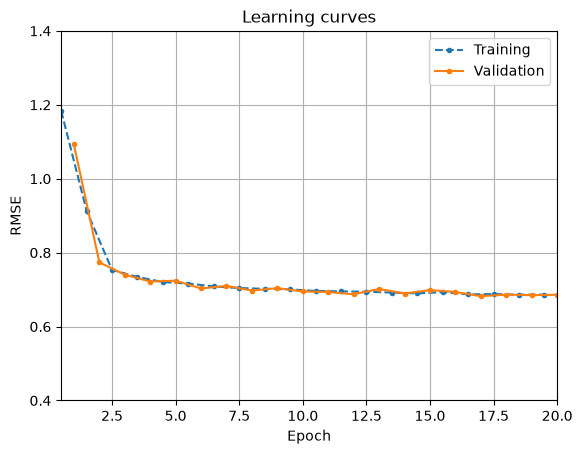

In [24]:
import matplotlib.pyplot as plt
import numpy as np
plt.plot(np.arange(20) + 0.5, history["train_metrics"][:20], ".--",
         label="Training")
plt.plot(np.arange(20) + 1.0, history["valid_metrics"][:20], ".-",
         label="Validation")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid()
plt.title("Learning curves")
plt.axis([0.5, 20, 0.4, 1.40])
plt.legend()
plt.show()